In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error



In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')



ticker = 'AAPL'     # ticker symbol for Apple

df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [3]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.271538,72.331694,71.029915,71.282568,135480400
2020-01-03,71.568924,72.326889,71.345145,71.501549,146322800
2020-01-06,72.139183,72.177684,70.442784,70.693036,118387200
2020-01-07,71.799919,72.403881,71.580950,72.148820,108872000
2020-01-08,72.954903,73.255683,71.503938,71.503938,132079200
...,...,...,...,...,...
2026-10-30,344.630005,349.190002,334.350006,346.720001,67841600
2026-11-02,338.320007,343.799988,335.820007,342.670013,64757700


<Axes: xlabel='Date'>

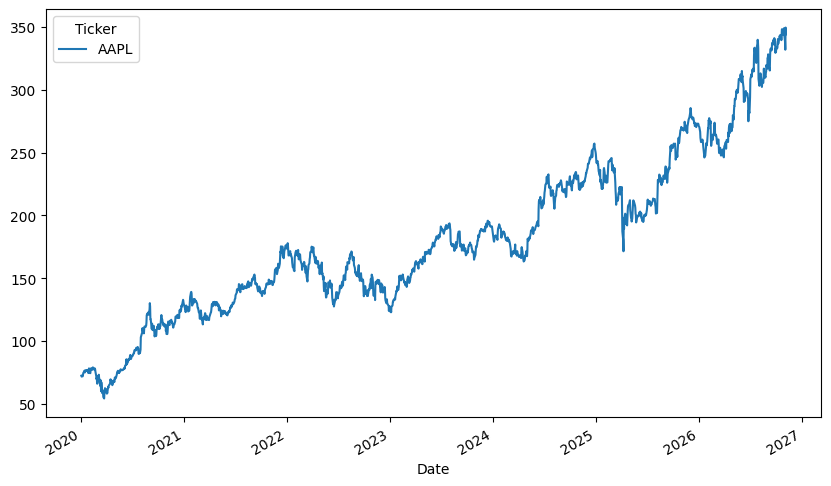

In [4]:

df.Close.plot(figsize=(10,6))

<Axes: xlabel='Date'>

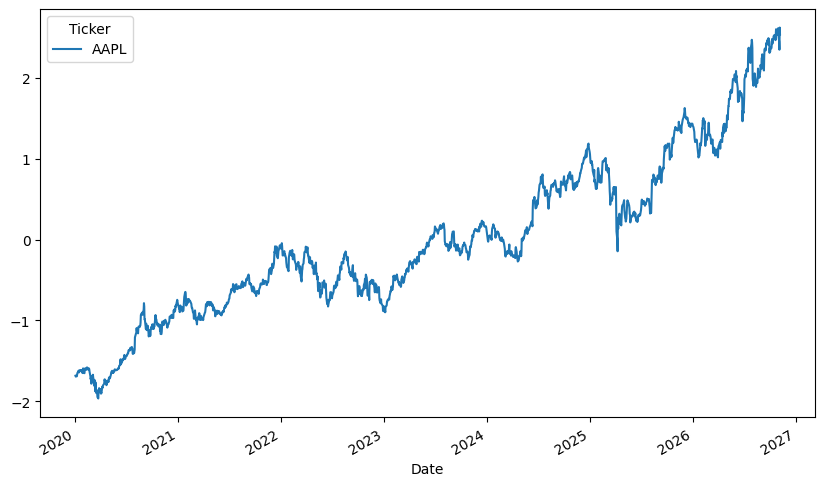

In [ ]:
scaler = StandardScaler()
df['Close'] = scaler.fit_transform(df['Close'])
df.Close.plot(figsize=(10,6))

In [14]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

train_size = int(0.8*len(data))

X_train = torch.from_numpy(data[:train_size, :-1,:]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1,:]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, :-1,:]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1,:]).type(torch.Tensor).to(device)


In [15]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim
        
        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first=True, dropout=0.0)
        self.fc = nn.Linear(hidden_dim, output_dim)
        
    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        
        out, (hn,cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        
        return out

In [16]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)


In [17]:
epochs = 200
for i in range(epochs):
    y_train_pred = model(X_train)
    loss = criterion(y_train_pred, y_train)
    
    if i % 20 == True:
        print(i, loss.item())
        
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

1 0.3913479745388031
21 0.009906105697154999
41 0.005268580745905638
61 0.0040991948917508125
81 0.0036761933006346226
101 0.003379636909812689
121 0.003113645827397704
141 0.002857718849554658
161 0.002614881843328476
181 0.0024112174287438393


In [19]:
model.eval()    # put the model on eval mode
y_test_pred = model(X_test)

print(type(y_train_pred))
print(type(y_train))
print(type(y_test_pred))
print(type(y_test))

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>


In [ ]:
y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())


In [22]:
train_rmse = root_mean_squared_error(y_train[:,0], y_train_pred[:,0])
test_rmse = root_mean_squared_error(y_test[:,0], y_test_pred[:,0])

print(train_rmse)
print(test_rmse)

3.0741513
9.673542


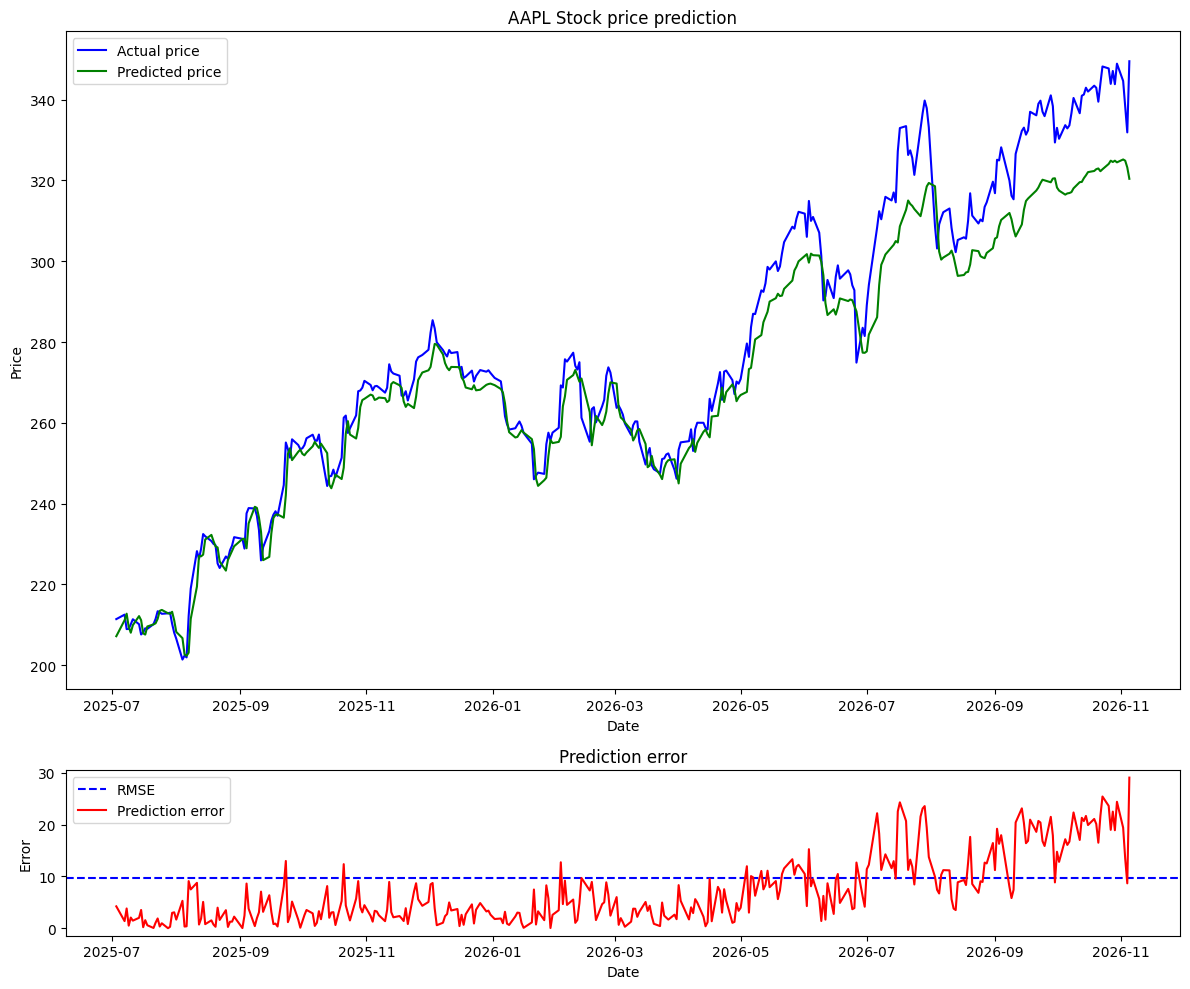

In [28]:
fig = plt.figure(figsize=(12,10))
gs = fig.add_gridspec(4, 1)
ax1 = fig.add_subplot(gs[:3,0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'Actual price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'Predicted price')
ax1.legend()
plt.title(f"{ticker} Stock price prediction")
plt.xlabel('Date')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label = 'RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test - y_test_pred), 'r', label = 'Prediction error')
ax2.legend()
plt.title('Prediction error')
plt.xlabel('Date')
plt.ylabel('Error')
plt.tight_layout()
plt.show()

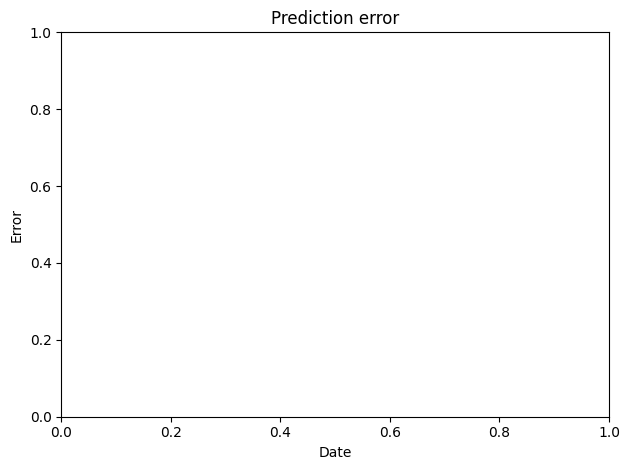